#Mini-project 1
##Items Recommendation using Apriori Algorithm in Python
###Weeks 2 and 3

In this exercise, you will be dealing with a dataset that has transactions by customers in a store and accordingly, you will use your knowledge of Data Science and AI and Customer Analytics to recommend grocery items to a customer that are most frequently bought together.

In this notebook, you will find some general flow of instructions that you can follow. In addition, you can add or try some additional steps to preprocess the data or visulaize it.

You first have to import the necessary libraries such as numpy,
matplot, and pandas. In addition, you have to import the apriori library.

In [1]:
#Imports
import numpy as np
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [2]:
#Read the dataset attached with this mini-project
from google.colab import drive
drive.mount('/content/drive')
import os

DATA_DIR = '/content/drive/MyDrive/Business Analytics April - June 2026'
data = pd.read_csv(os.path.join(DATA_DIR, 'Dataset_market_apriori.csv'))


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Mounted at /content/drive


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Now that the dataset is ready, you have to explore it which is a very important step in any data science related problem. Below some suggestions of interesting plots from this dataset; however, you can explore it further.

In [3]:
data.info()

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   shrimp             7500 non-null   object 
 1   almonds            5746 non-null   object 
 2   avocado            4388 non-null   object 
 3   vegetables mix     3344 non-null   object 
 4   green grapes       2528 non-null   object 
 5   whole weat flour   1863 non-null   object 
 6   yams               1368 non-null   object 
 7   cottage cheese     980 non-null    object 
 8   energy drink       653 non-null    object 
 9   tomato juice       394 non-null    object 
 10  low fat yogurt     255 non-null    object 
 11  green tea          153 non-null    object 
 12  honey              86 non-null     object 
 13  salad              46 non-null     object 
 14  mineral water      24 non-null     object 
 15  salmon             7 non-null      object 
 16  antioxydant juice  3 non

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [4]:
#of course run .head() to check the first 5 rows in the data
print(data.head())

           shrimp    almonds     avocado    vegetables mix green grapes  \
0         burgers  meatballs        eggs               NaN          NaN   
1         chutney        NaN         NaN               NaN          NaN   
2          turkey    avocado         NaN               NaN          NaN   
3   mineral water       milk  energy bar  whole wheat rice    green tea   
4  low fat yogurt        NaN         NaN               NaN          NaN   

  whole weat flour yams cottage cheese energy drink tomato juice  \
0              NaN  NaN            NaN          NaN          NaN   
1              NaN  NaN            NaN          NaN          NaN   
2              NaN  NaN            NaN          NaN          NaN   
3              NaN  NaN            NaN          NaN          NaN   
4              NaN  NaN            NaN          NaN          NaN   

  low fat yogurt green tea honey salad mineral water salmon antioxydant juice  \
0            NaN       NaN   NaN   NaN           NaN    NaN

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

**To Answer: **

What do the different rows and columns represent in this dataset?

Rows: Each row represents a single customer transaction. Think of it as one shopping basket filled with items.


Columns: Each column can be thought of as a slot for an item within that transaction. The column headers (like 'shrimp', 'almonds', 'avocado') are not distinct categories, but rather placeholders for items purchased within that transaction. If a cell contains a value (e.g., 'burgers', 'meatballs'), it means that specific item was part of that transaction. If it contains NaN (Not a Number, representing missing data), it means that particular item was not purchased in that specific transaction.

In [5]:
data.describe()

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

,olive oil
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In almost any business, some items are more popular than other items! There are many factors that can contribute to the popularity of a particular item, including:


*   Demand: If there is high demand for a particular item, it is more likely to be popular among customers.
*   Trendiness: Some items become popular because they are on-trend or fashionable at the time. For example, certain types of clothing or accessories may become popular because they are seen as cool or stylish.
*   Marketing: Effective marketing campaigns can help make an item more popular by increasing its visibility and desirability among potential customers.
*   Price: If an item is priced competitively, it may be more popular than a similar item that is priced higher.
*   Quality: If an item is of high quality and delivers on its promises, it is more likely to be popular among customers.
*   Availability: If an item is readily available and easy to find, it may be more popular than a similar item that is harder to find.

Ultimately, the popularity of an item can have a significant impact on the success of a business, so it is important for business owners to pay attention to the factors that contribute to popularity and work to promote and sell the items that are most in demand.

So let's figure out what's going on in this business!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

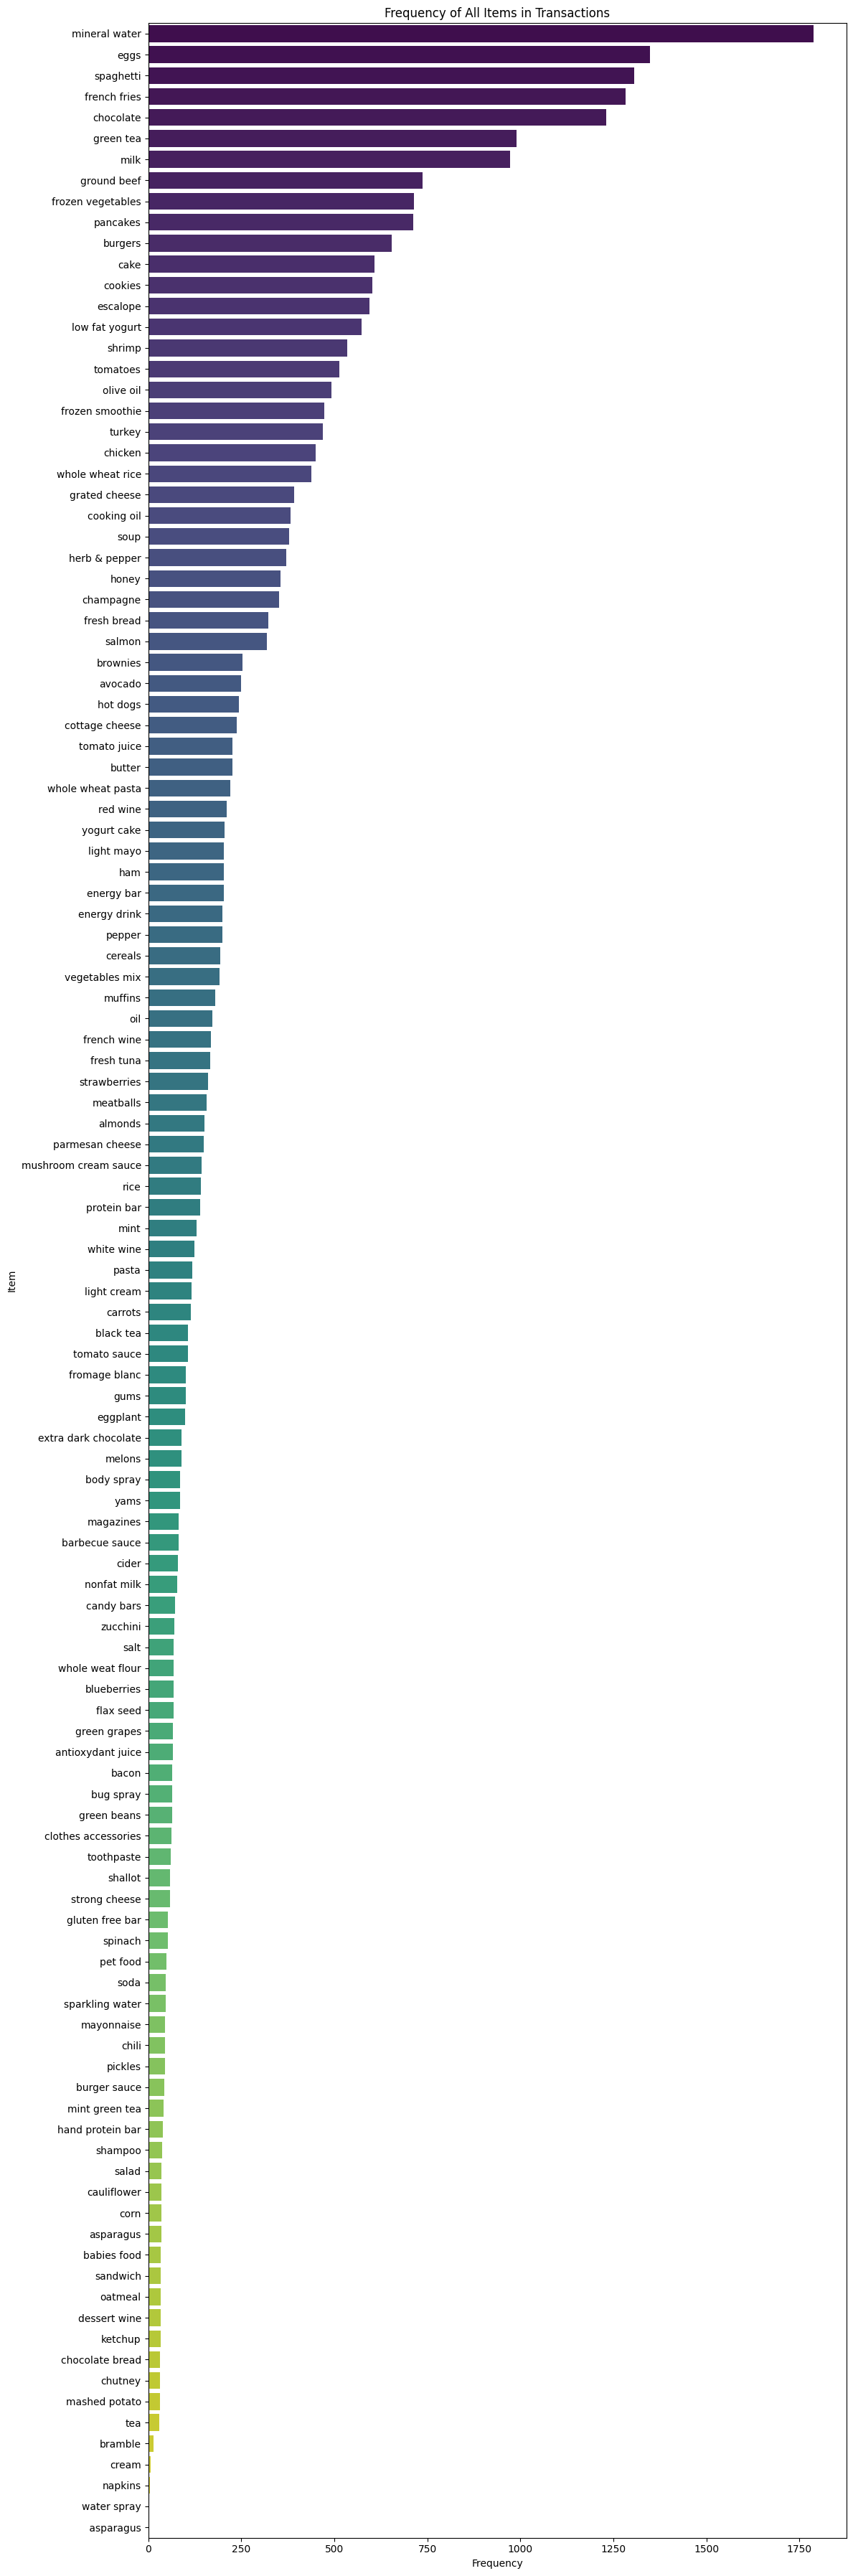

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [6]:
#Draw a barplot (using plot.bar) that shows the frequency of each item in this business
#Do not forget to add a title and axes titles as well
import matplotlib.pyplot as plt
import seaborn as sns

# Melt the DataFrame to get all items into a single column
items_melted = data.melt(value_name='item').dropna(subset=['item'])

# Count the frequency of each item
item_counts = items_melted['item'].value_counts()

# Plotting all items
# Adjust figure size to accommodate all items for better readability
plt.figure(figsize=(12, item_counts.shape[0] * 0.3))
sns.barplot(x=item_counts.values, y=item_counts.index, palette='viridis')
plt.title('Frequency of All Items in Transactions')
plt.xlabel('Frequency')
plt.ylabel('Item')
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

Now, you will visualize using Treemaps.

Treemaps are a type of visual representation that displays hierarchical data as nested rectangles, with the size of each rectangle proportional to a specific value or attribute.
In business, treemaps can be used to display data such as market share, sales figures, or website traffic. For example, a treemap could be used to display the market share of various product categories within a company, with each rectangle representing a product category and the size of the rectangle indicating the relative market share of that category.

Treemaps can also be used to analyze and compare data across different time periods, regions, or other dimensions. For example, a treemap could be used to compare website traffic by region, with each rectangle representing a different region and the size of the rectangle indicating the relative amount of website traffic from that region.
Overall, treemaps can be a useful tool for businesses to quickly and easily visualize and analyze large amounts of data in a hierarchical and visually appealing way.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

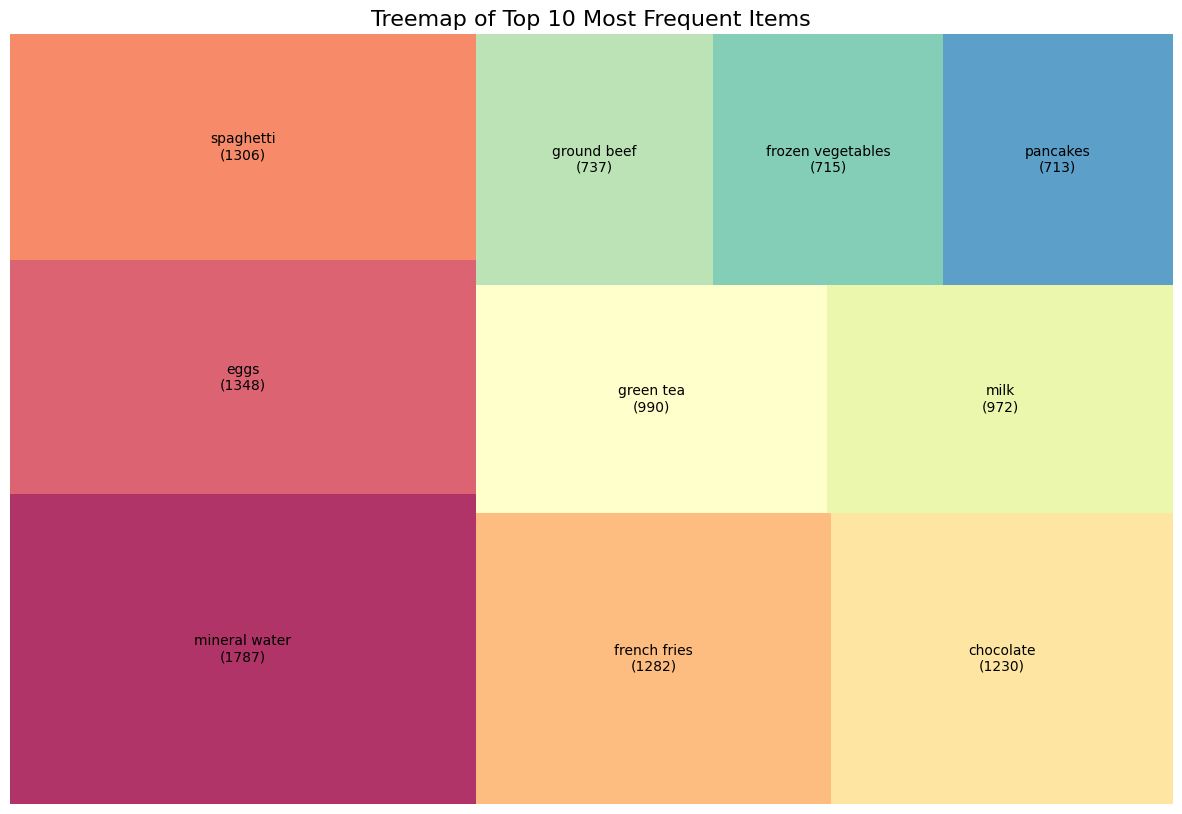

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [7]:
#Another way to visualize the most frequent items is through a tree map which can be imported from squarify library
!pip install squarify
import squarify

# Filter for items that appear at least once
filtered_item_counts = item_counts[item_counts > 0]

# Choose the number of items to display in the treemap, for example, the top 50 or adjust as needed
# For this dataset, let's consider a reasonable number that fits well visually, e.g., top 8
top_n = 10
treemap_data = filtered_item_counts.head(top_n)

# Prepare data for squarify
sizes = treemap_data.values
label_items = treemap_data.index.tolist()

# Generate labels with item names and their frequencies
labels = [f'{item}\n({count})' for item, count in zip(label_items, sizes)]

# Define colors
colors = [plt.cm.Spectral(i / float(len(labels))) for i in range(len(labels))]

# Create the treemap
plt.figure(figsize=(15, 10))
squarify.plot(sizes=sizes, label=labels, color=colors, alpha=0.8)
plt.title(f'Treemap of Top {top_n} Most Frequent Items', fontsize=16)
plt.axis('off') # Remove axes
plt.show()

##Get the list of transactions
After reading the dataset, we will extract the items in each transaction by using two nested loops. The first loop will iterate through the total number of transactions, while the second loop will iterate through the total number of columns in each transaction. The resulting list of items will serve as the training set from which we can generate the list of association rules.



To train an apriori model, which requires data in a list format, we must convert our pandas' data frame into a transaction list. To do this, we first initialize an empty list, and then add the transactions from our pandas' data frame to it.

To accomplish this, we will use a for-loop function to iterate through each observation in our pandas' dataset and add its elements to our empty list using the append function.
However, to achieve this, we will need to use two nested for-loops. The first loop will iterate through all 7501 transactions, while the second loop will iterate through all 20 columns. This will allow the append function to add each element to the list independently.

Now that we have the `transactions` list, we need to convert it into a one-hot encoded DataFrame. This format is suitable for the `apriori` function from `mlxtend`.

In [8]:
transactions = []
for i in range(0, data.shape[0]):
    transactions.append(data.iloc[i].dropna().tolist())
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_transactions = pd.DataFrame(te_ary, columns=te.columns_)

print("Shape of the one-hot encoded DataFrame:", df_transactions.shape)
display(df_transactions.head())

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Shape of the one-hot encoded DataFrame: (7500, 120)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,asparagus,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,...,turkey,vegetables mix,water spray,white wine,whole weat flour,whole wheat pasta,whole wheat rice,yams,yogurt cake,zucchini
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,True,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

##Applying Apriori

Apriori is a popular algorithm used in market basket analysis to discover association rules between items purchased together by customers. It is based on the principle that if an itemset is frequent, then all of its subsets must also be frequent. In other words, if a customer frequently buys items A and B together, then they are likely to also frequently buy items A and C together, or items B and C together.

The Apriori algorithm works by first identifying all the frequent itemsets in the dataset, i.e., itemsets that occur above a predefined minimum support threshold. It then generates association rules from these frequent itemsets by calculating their corresponding confidence and lift scores.

The confidence score measures the probability of buying the consequent item given that the antecedent item is bought, while the lift score measures the strength of the association between the antecedent and consequent items. The resulting association rules can be used to make recommendations to customers or to optimize product placement in stores to increase sales.




In [12]:
# Apply Apriori to find frequent itemsets
frequent_itemsets = apriori(df_transactions, min_support=0.0045, use_colnames=True) #Use a minimum support of 0.0045

# Generate association rules
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.2) #Use a minimum confidence of 0.2

# Filter rules by lift and length
rules = rules[(rules['lift'] >= 3) & (rules['antecedents'].apply(lambda x: len(x)) >= 2)] #Use a minimum lift of 3 #Use a minimum length of 2

#convert the rules found by the apriori class into a list since it is easier to view the results in this form.
rules_list = rules.to_dict('records')

#Let's first find the total number of rules mined by the apriori class.
print(f"Total number of association rules mined (from rules_list): {len(rules_list)}")

#print the first rule. Do not forget that the index starts with 0 in Python!
print(rules_list[0])



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Total number of association rules mined (from rules_list): 21
{'antecedents': frozenset({'frozen vegetables', 'chocolate'}), 'consequents': frozenset({'shrimp'}), 'antecedent support': 0.022933333333333333, 'consequent support': 0.07133333333333333, 'support': 0.005333333333333333, 'confidence': 0.23255813953488372, 'lift': 3.260160834601174, 'representativity': 1.0, 'leverage': 0.003697422222222222, 'conviction': 1.210080808080808, 'zhangs_metric': 0.7095387554585153, 'jaccard': 0.05997001499250374, 'certainty': 0.1736089083290205, 'kulczynski': 0.1536622473375353}


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Result analysis:
The first association rule highlights that customers who buy chocolate and frozen vegetables are also likely to buy shrimp. This co-occurrence happens in 0.53% of transactions (support). If a customer buys chocolate and frozen vegetables, there's a 23.26% chance they'll also buy shrimp (confidence). Most significantly, these customers are 3.26 times more likely to buy shrimp than the average customer (lift), indicating a strong positive association.**To Answer**
Analyze the obtained result.


###To analyze further, print the items in the list of associate rules and

In [13]:
#Do a for loop for all items in the association rules and print the pairs of items in each.
#Then show the support, confidence and lift of each.

for rule in rules_list:
    antecedents = ', '.join(list(rule['antecedents']))
    consequents = ', '.join(list(rule['consequents']))
    support = rule['support']
    confidence = rule['confidence']
    lift = rule['lift']
    print(f"Rule: {{{antecedents}}} -> {{{consequents}}}, Support: {support:.4f}, Confidence: {confidence:.4f}, Lift: {lift:.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Rule: {frozen vegetables, chocolate} -> {shrimp}, Support: 0.0053, Confidence: 0.2326, Lift: 3.2602
Rule: {chocolate, shrimp} -> {frozen vegetables}, Support: 0.0053, Confidence: 0.2963, Lift: 3.1080
Rule: {cooking oil, ground beef} -> {spaghetti}, Support: 0.0048, Confidence: 0.5714, Lift: 3.2816
Rule: {cooking oil, spaghetti} -> {ground beef}, Support: 0.0048, Confidence: 0.3025, Lift: 3.0786
Rule: {frozen vegetables, spaghetti} -> {ground beef}, Support: 0.0087, Confidence: 0.3110, Lift: 3.1649
Rule: {frozen vegetables, milk} -> {olive oil}, Support: 0.0048, Confidence: 0.2034, Lift: 3.0942
Rule: {olive oil, frozen vegetables} -> {milk}, Support: 0.0048, Confidence: 0.4235, Lift: 3.2680
Rule: {mineral water, shrimp} -> {frozen vegetables}, Support: 0.0072, Confidence: 0.3068, Lift: 3.2184
Rule: {frozen vegetables, spaghetti} -> {olive oil}, Support: 0.0057, Confidence: 0.2057, Lift: 3.1299
Rule: {frozen vegetables, spaghetti} -> {shrimp}, Support: 0.0060, Confidence: 0.2153, Lift: 3

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Analyze some of these rules. In addition, try to change the parameters we used in the apriori algorithm to check the effect on the results.

### Experimenting with Apriori Parameters

The `apriori` algorithm relies on several key parameters that significantly influence the number and type of association rules discovered:

*   **`min_support`**: This threshold determines the minimum frequency an itemset must have to be considered "frequent." A lower `min_support` will result in more frequent itemsets and potentially more rules, but can also lead to a combinatorial explosion. A higher `min_support` will yield fewer, but more common, itemsets and rules.

*   **`min_confidence`**: This threshold dictates the minimum probability that the consequent item(s) will be purchased given the antecedent item(s). A lower `min_confidence` will generate more rules (even weaker associations), while a higher value will filter out less reliable rules.

*   **`min_lift`**: Lift measures how much more likely the consequent is to be purchased when the antecedent is purchased, compared to its baseline probability. A `lift` greater than 1 indicates a positive association. Increasing `min_lift` will focus on stronger, more interesting relationships, filtering out rules that might occur by chance or have weak correlations.

In [14]:
# Define your parameters here to experiment
new_min_support = 0.003  # Example: try reducing this to 0.003 or increasing to 0.006
new_min_confidence = 0.15  # Example: try reducing to 0.15 or increasing to 0.3
new_min_lift = 4          # Example: try reducing to 1.5 or increasing to 4

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [15]:
# Apply Apriori with new parameters
frequent_itemsets_new = apriori(df_transactions, min_support=new_min_support, use_colnames=True)

# Generate association rules with new parameters
rules_new = association_rules(frequent_itemsets_new, metric="confidence", min_threshold=new_min_confidence)

# Filter rules by lift and length with new parameters
rules_new = rules_new[(rules_new['lift'] >= new_min_lift) & (rules_new['antecedents'].apply(lambda x: len(x)) >= 2)]

# Convert to list for display
rules_list_new = rules_new.to_dict('records')

print(f"Total number of association rules mined with new parameters: {len(rules_list_new)}")
print("\nFirst 5 new rules (if any):")
if len(rules_list_new) > 0:
    for i, rule in enumerate(rules_list_new[:5]): # Print up to the first 5 rules
        antecedents = ', '.join(list(rule['antecedents']))
        consequents = ', '.join(list(rule['consequents']))
        support = rule['support']
        confidence = rule['confidence']
        lift = rule['lift']
        print(f"Rule {i+1}: {{{antecedents}}} -> {{{consequents}}}, Support: {support:.4f}, Confidence: {confidence:.4f}, Lift: {lift:.4f}")
else:
    print("No rules found with the specified parameters. Try adjusting them.")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Total number of association rules mined with new parameters: 33

First 5 new rules (if any):
Rule 1: {frozen vegetables, cake} -> {tomatoes}, Support: 0.0031, Confidence: 0.2987, Lift: 4.3670
Rule 2: {cereals, spaghetti} -> {ground beef}, Support: 0.0031, Confidence: 0.4600, Lift: 4.6811
Rule 3: {herb & pepper, chocolate} -> {ground beef}, Support: 0.0040, Confidence: 0.4412, Lift: 4.4896
Rule 4: {ground beef, eggs} -> {herb & pepper}, Support: 0.0041, Confidence: 0.2067, Lift: 4.1779
Rule 5: {french fries, herb & pepper} -> {ground beef}, Support: 0.0032, Confidence: 0.4615, Lift: 4.6968


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Experiment result analysis:


By adjusting the parameters to a min_support of 0.003, min_confidence of 0.15, and min_lift of 4, we have increased the total number of association rules mined from 21 to 33.

This increase is primarily due to the lower min_support and min_confidence thresholds, which allow for more itemsets and rules to be considered frequent and strong enough. The higher min_lift (from 3 to 4) filters for even stronger positive associations.

Let's look at some of the new rules:

Rule 1: {frozen vegetables, cake} -> {tomatoes}: This rule has a support of 0.0031 and a high lift of 4.3670. It suggests that customers buying frozen vegetables and cake are over 4 times more likely to also buy tomatoes.
Rule 2: {cereals, spaghetti} -> {ground beef}: With a support of 0.0031 and an impressive lift of 4.6811, this indicates a very strong positive correlation between purchasing cereals and spaghetti, and also buying ground beef.
Rule 5: {herb & pepper, french fries} -> {ground beef}: This rule also shows a high lift of 4.6968, suggesting a strong likelihood of customers buying ground beef if they are already buying herb & pepper and french fries.
These new rules reveal some potentially interesting and stronger relationships that were not captured by the previous, more stringent parameters. The increased lift value means we are focusing on associations that are less likely to occur by chance.


#After covering the last lecture in this module, you will know more about the challenges of Apriori.

Although Apriori is a widely used algorithm in data mining, it has several challenges, including:
* Memory requirements: Apriori requires a lot of memory to store large transactional datasets, especially when dealing with frequent itemsets.
* Combinatorial explosion: The Apriori algorithm generates a large number of candidate itemsets, which increases exponentially with the number of items in the dataset. This results in a combinatorial explosion, making it difficult to handle large datasets.
* Time complexity: The Apriori algorithm has a high time complexity, especially when the minimum support threshold is low. It requires multiple passes through the dataset to generate frequent itemsets, which can be time-consuming for large datasets.
* Scalability: Apriori may not be scalable for large datasets, as the algorithm's performance degrades with increasing data size.
* Apriori requires prior knowledge of minimum support: Apriori requires prior knowledge of minimum support, which is the threshold frequency of an itemset that determines whether it is considered frequent or not. Determining the appropriate minimum support value can be challenging, as a low value may result in generating too many frequent itemsets, while a high value may result in missing important associations.
* Apriori may generate redundant rules: The Apriori algorithm may generate redundant rules, which are rules that convey the same information. These rules can make it difficult to interpret the results and identify meaningful associations.
* Apriori is not suitable for datasets with rare items: The Apriori algorithm performs poorly on datasets with rare items, as infrequent items may not appear in any frequent itemsets, resulting in a high number of false negatives.


To solve some of these problems. We can use FP-Growth.

Go over the following paper to know more about FP-Growth:

https://www.cs.sfu.ca/~jpei/publications/sigmod00.pdf

and implement it here in Python on the same dataset. You can use existing libraries and functions of fpgrowth such as:

from mlxtend.frequent_patterns import fpgrowth

### Implementing FP-Growth

FP-Growth (Frequent Pattern Growth) is an alternative to the Apriori algorithm for mining frequent itemsets. It aims to overcome some of Apriori's limitations, particularly its candidate generation overhead. FP-Growth uses a tree structure called an FP-tree to compactly represent the dataset and mine frequent itemsets without explicit candidate generation.

Here, we will use the `fpgrowth` function from the `mlxtend.frequent_patterns` library, applying it to our `df_transactions` DataFrame.

In [16]:
# Import fpgrowth
from mlxtend.frequent_patterns import fpgrowth

# Apply FP-Growth to find frequent itemsets
# We'll start with a similar min_support to the Apriori example (0.0045)
frequent_itemsets_fp = fpgrowth(df_transactions, min_support=0.0045, use_colnames=True)

print("Frequent Itemsets found with FP-Growth (first 5):")
display(frequent_itemsets_fp.head())

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Frequent Itemsets found with FP-Growth (first 5):


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.179733,(eggs)
1,0.087200,(burgers)
2,0.020933,(meatballs)
3,0.062533,(turkey)
4,0.033200,(avocado)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [18]:
# Generate association rules from FP-Growth frequent itemsets
# Using similar parameters for confidence and lift as before
rules_fp = association_rules(frequent_itemsets_fp, metric="confidence", min_threshold=0.2)

# Filter rules by lift and length (minimum lift of 3, minimum antecedent length of 2)
rules_fp = rules_fp[(rules_fp['lift'] >= 3) & (rules_fp['antecedents'].apply(lambda x: len(x)) >= 2)]

# Convert to list for display
rules_list_fp = rules_fp.to_dict('records')

print(f"Total number of association rules mined with FP-Growth: {len(rules_list_fp)}")
print("\nFirst 5 FP-Growth rules (if any):")

if len(rules_list_fp) > 0:
    for i, rule in enumerate(rules_list_fp[:5]): # Print up to the first 5 rules
        antecedents = ', '.join(list(rule['antecedents']))
        consequents = ', '.join(list(rule['consequents']))
        support = rule['support']
        confidence = rule['confidence']
        lift = rule['lift']
        print(f"Rule {i+1}: {{{antecedents}}} -> {{{consequents}}}, Support: {support:.4f}, Confidence: {confidence:.4f}, Lift: {lift:.4f}")
else:
    print("No rules found with the specified parameters using FP-Growth. Try adjusting them.")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Total number of association rules mined with FP-Growth: 21

First 5 FP-Growth rules (if any):
Rule 1: {soup, mineral water} -> {olive oil}, Support: 0.0052, Confidence: 0.2254, Lift: 3.4295
Rule 2: {spaghetti, milk, mineral water} -> {frozen vegetables}, Support: 0.0045, Confidence: 0.2881, Lift: 3.0224
Rule 3: {frozen vegetables, spaghetti} -> {ground beef}, Support: 0.0087, Confidence: 0.3110, Lift: 3.1649
Rule 4: {cooking oil, ground beef} -> {spaghetti}, Support: 0.0048, Confidence: 0.5714, Lift: 3.2816
Rule 5: {cooking oil, spaghetti} -> {ground beef}, Support: 0.0048, Confidence: 0.3025, Lift: 3.0786


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### Gained Insights into Customer Purchasing Behavior:

1.  **Meal-Oriented Shopping**: Many rules suggest customers shop for specific meals. For example:
    *   `{cooking oil, ground beef} -> {spaghetti}` and `{cooking oil, spaghetti} -> {ground beef}` indicate a strong tendency to buy these items together for a meal.
    *   `{herb & pepper, spaghetti} -> {ground beef}` and `{french fries, herb & pepper} -> {ground beef}` further solidify that ground beef is often part of a planned meal, with customers also picking up seasonings and sides.
    *   `{spaghetti, grated cheese} -> {ground beef}` highlights that cheese is a common accompaniment for pasta dishes involving ground beef.

2.  **Complementary Fresh/Frozen Produce**: Frozen vegetables appear frequently as an antecedent or consequent with various items, suggesting they are a versatile add-on to many shopping carts:
    *   `{frozen vegetables, spaghetti} -> {ground beef}`
    *   `{frozen vegetables, milk} -> {olive oil}`
    *   Interestingly, `{frozen vegetables, chocolate} -> {shrimp}` suggests a specific (perhaps gourmet or dietary) combination for a certain customer segment.

3.  **Staple Item Associations**: Items like mineral water, milk, spaghetti, and olive oil frequently appear in rules, indicating their role as essential purchases around which other items are bought.
    *   `{soup, mineral water} -> {olive oil}` points to a pattern related to healthy or light meal preparation.

4.  **Stronger, Niche Associations**: When we adjusted the parameters (especially increasing `min_lift`), we found rules with very high lift, indicating strong, less obvious relationships:
    *   `{frozen vegetables, cake} -> {tomatoes}` (Lift: 4.3670) is a unique combination that implies a specific type of shopper or recipe.
    *   `{cereals, spaghetti} -> {ground beef}` (Lift: 4.6811) is another interesting, highly correlated group that might not be intuitively obvious.

### Useful Marketing Strategies for Businesses:

1.  **Product Bundling and Combo Deals**: Create themed bundles based on strong association rules.
    *   **"Italian Night" Bundle**: Offer discounts on spaghetti, ground beef, cooking oil, and grated cheese when purchased together.
    *   **"Healthy Meal Starter" Kit**: Combine frozen vegetables, shrimp, and olive oil.
    *   Consider a unique bundle for `{frozen vegetables, cake, tomatoes}` if further analysis reveals a strong segment for it.

2.  **Strategic Product Placement**: Arrange items in the store to encourage co-purchases.
    *   Place spaghetti, cooking oil, and grated cheese adjacent to the meat (ground beef) section.
    *   Position herb & pepper and French fries near ground beef.
    *   Place olive oil displays close to soup, milk, and frozen vegetables.
    *   If the `frozen vegetables + chocolate + shrimp` rule is significant, consider cross-merchandising these items (e.g., a special display in the frozen aisle or near seafood).

3.  **Targeted Promotions and Advertising**: Use these rules to personalize marketing efforts.
    *   If a customer buys cereals and spaghetti, send them a digital coupon for ground beef.
    *   Advertise recipes that incorporate highly correlated items, especially for the less intuitive combinations like `{frozen vegetables, cake} -> {tomatoes}`.

4.  **Optimized Inventory Management**: Ensure that items frequently bought together are always in stock, particularly for high-lift combinations. This prevents lost sales when a customer can't complete their intended purchase.

5.  **In-Store Signage and Recipe Suggestions**: Use signage in relevant aisles to suggest complementary items or provide simple recipe ideas that feature the associated products. For example, near the ground beef, a sign could say: "Pair with Spaghetti, Cooking Oil & Grated Cheese for a perfect weeknight meal!"

### Summary Report: Marketing Strategies from Association Rules

**Overall Goal:** Increase sales and enhance customer experience by leveraging insights from item co-occurrence patterns.

**Key Strategies:**

1.  **Product Bundling & Combo Deals:**
    *   Create themed bundles (e.g., "Italian Night" with spaghetti, ground beef, cooking oil, grated cheese).
    *   Offer discounts on complementary items purchased together.

2.  **Strategic Product Placement:**
    *   Arrange related items physically close in-store (e.g., pasta near meat, herbs/spices near relevant dishes).
    *   Use cross-merchandising displays for less obvious but strong associations.

3.  **Targeted Promotions & Advertising:**
    *   Personalize marketing campaigns (e.g., digital coupons for ground beef to customers buying cereals and spaghetti).
    *   Promote recipes featuring highly correlated items, especially unique combinations.

4.  **Optimized Inventory Management:**
    *   Ensure consistent stock of items frequently bought together, particularly for high-lift product pairs.

5.  **In-Store Signage & Recipe Suggestions:**
    *   Use clear signage to suggest complementary products or provide simple recipe ideas in relevant aisles.